# Session 2: Normal Distribution Probabilities

*ECE 225A, Module 04 (The Normal Distribution), deck 8.Normal_distribution-probabilities, slides 1-17*

Session 1 established the normal density. To use it, we need probabilities of intervals, and those require the CDF, which has no closed form. This looks like a serious problem, since it seems that a separate table is needed for every $\mu$ and $\sigma$. It is not. One table for the standard normal, covering only nonnegative values, is enough: symmetry handles the negative values, and standardizing handles every other normal. The second half of the session draws the main conclusion of this reduction. For a normal variable, the chance of landing within $\alpha$ standard deviations of the mean depends only on $\alpha$, which gives the 68-95-99.7 rule and a sense of how rare far-out values really are.

## Learning objectives

After this session you should be able to:

1. Define $\Phi(z)$, explain why it needs a table or program, and read values from the Z table.
2. Compute $P(Z \le a)$, $P(Z \ge a)$, and $P(a \le Z \le b)$, for positive and negative $a$ and $b$, using $\Phi(-a) = 1 - \Phi(a)$.
3. Standardize any $X \sim N(\mu, \sigma^2)$ to a Z score, and use it to compute interval probabilities.
4. Explain why $P(\lvert X - \mu \rvert \ge \sigma)$ varies across distributions, but not across normal distributions.
5. Bound $P(\lvert Z \rvert \le 1)$ by simple areas, and derive the 68-95-99.7 rule from the table.
6. Convert tail probabilities into expected waiting times, and explain the idea behind six sigma.

## Prerequisites

- The CDF and interval probabilities for continuous variables (Module 01, Session 5).
- The normal density, its symmetry, and $aX + b \sim N(a\mu + b, a^2\sigma^2)$ (Session 1).
- The mean $1/p$ of a geometric waiting time (Module 01, Session 5).

In [1]:
from math import e, exp, pi, sqrt

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(225)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, FAINT, GRID = "#0b0b0b", "#52514e", "#c3c2b7", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})

Phi, phi = norm.cdf, norm.pdf

## 1. The cumulative distribution function (slides 1-2)

Intervals come in three types: **less** ($X \le a$), **more** ($X \ge b$), and **between** ($a \le X \le b$). A single function determines the probabilities of all of them, the **cumulative distribution function**:

$$F(x) \triangleq P(X \le x) = \int_{-\infty}^{x} f(u)\, du.$$

## 2. The normal CDF (slide 3)

For $X \sim N_{\mu,\sigma^2}$,

$$F_{\mu,\sigma^2}(x) \triangleq P(X \le x) = \int_{-\infty}^{x} \frac{1}{\sqrt{2\pi\sigma^2}}\, e^{-\frac{(u - \mu)^2}{2\sigma^2}}\, du.$$

Two worries arise:

1. **No closed form.** $e^{-x^2}$ has no elementary antiderivative, so we need a program or a table.
2. **One for each $\mu, \sigma$?** Since those parameters vary continuously, this would be hopeless.

The second worry disappears: **one CDF determines all $F_{\mu,\sigma}$**, namely the standard normal CDF,

$$F_{0,1}(z) = P(Z \le z) = \int_{-\infty}^{z} \phi(u)\, du = \int_{-\infty}^{z} \frac{1}{\sqrt{2\pi}}\, e^{-u^2/2}\, du \triangleq \Phi(z).$$

The capital letter marks the step from the density $\phi$ to its integral $\Phi$. (The slide's exponent here still shows $(u - \mu)^2$, which should read $u^2$.)

## 3. The Z table (slide 4)

$\Phi$ has no known formula, so we use a table or a computer. The **standard normal table**, or **Z table**, lists $\Phi(z)$ for $z \ge 0$. A row gives the first decimal, and a column gives the second:

| Value | Row and column | Entry |
|---|---|---|
| $\Phi(0)$ | $0.0$ and $.00$ | $.5000$ |
| $\Phi(1.4)$ | $1.4$ and $.00$ | $.9192$ |
| $\Phi(1.82)$ | $1.8$ and $.02$ | $.9656$ |
| $\Phi(3.49)$ | $3.4$ and $.09$ | $.9998$ |

In [2]:
for z in [0, 1.4, 1.82, 3.49]:
    print(f"Phi({z:<4}) = {Phi(z):.4f}")

# The upper-left corner of the table, built from the program.
print("\n  z  " + "".join(f"  .{c:02d}  " for c in range(5)))
for r in [0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0]:
    print(f"{r:4.1f} " + "".join(f" {Phi(r + c / 100):.4f}" for c in range(5)))

Phi(0   ) = 0.5000
Phi(1.4 ) = 0.9192
Phi(1.82) = 0.9656
Phi(3.49) = 0.9998

  z    .00    .01    .02    .03    .04  
 0.0  0.5000 0.5040 0.5080 0.5120 0.5160
 0.5  0.6915 0.6950 0.6985 0.7019 0.7054
 1.0  0.8413 0.8438 0.8461 0.8485 0.8508
 1.5  0.9332 0.9345 0.9357 0.9370 0.9382
 2.0  0.9772 0.9778 0.9783 0.9788 0.9793
 2.5  0.9938 0.9940 0.9941 0.9943 0.9945
 3.0  0.9987 0.9987 0.9987 0.9988 0.9988


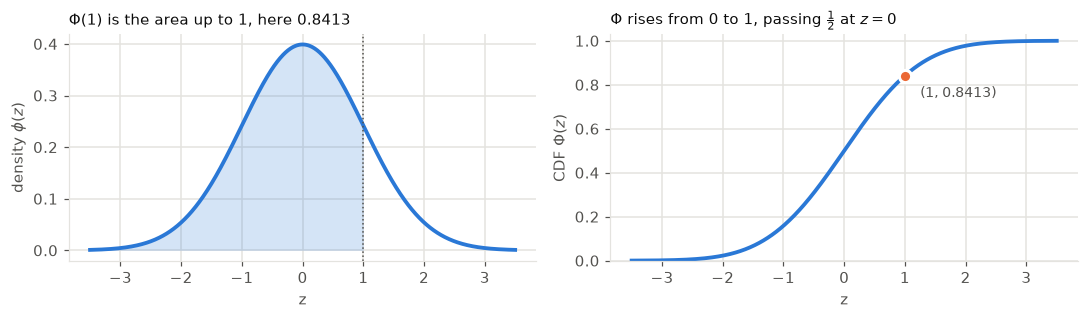

In [3]:
zs = np.linspace(-3.5, 3.5, 701)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
a = 1.0

axes[0].plot(zs, phi(zs), color=BLUE, lw=2.5)
axes[0].fill_between(zs, phi(zs), where=zs <= a, color=BLUE, alpha=0.2, lw=0)
axes[0].axvline(a, color=MUTED, lw=1, ls=":")
axes[0].set(xlabel="z", ylabel=r"density $\phi(z)$")
axes[0].set_title(rf"$\Phi({a:g})$ is the area up to {a:g}, here {Phi(a):.4f}", color=INK, loc="left", fontsize=10)

axes[1].plot(zs, Phi(zs), color=BLUE, lw=2.5)
axes[1].plot([a], [Phi(a)], "o", color=ORANGE, ms=8, mec="white", mew=2, zorder=3)
axes[1].annotate(f"({a:g}, {Phi(a):.4f})", (a, Phi(a)), xytext=(10, -14), textcoords="offset points", color=MUTED, fontsize=9)
axes[1].set(xlabel="z", ylabel=r"CDF $\Phi(z)$", ylim=(0, 1.03))
axes[1].set_title(r"$\Phi$ rises from 0 to 1, passing $\frac{1}{2}$ at $z = 0$", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 4. Using the Z table (slide 5)

Let $Z \sim N(0, 1)$. For nonnegative values the table is direct:

| Event | Probability | Example with the table |
|---|---|---|
| $Z \le a$ | $\Phi(a)$ | $P(Z \le 1) = \Phi(1) \approx 0.84$ |
| $Z \ge a$ | $1 - \Phi(a)$ | $P(Z \ge 1) \approx 1 - 0.84 = 0.16$ |
| $a \le Z \le b$ | $\Phi(b) - \Phi(a)$ | $P(1 \le Z \le 2) \approx 0.9772 - 0.8413 = 0.1359$ |

What about $P(Z \le -1)$, that is, $\Phi(-1)$? The table has no such row.

## 5. Quiz: the missing half (slide 6)

**Question.** The table gives $\Phi(a)$ for $a \ge 0$. What about $a < 0$?

**A warm-up.** Take a density $f$ with CDF $F$, and suppose $F(2) = 0.6$. What can we say about $F(-2)$? For an arbitrary density, only that $0 \le F(-2) \le F(2) = 0.6$.

**If $f$ is symmetric around 0,** we can say exactly what it is:

$$F(-2) = P(X \le -2) = P(X \ge 2) = 1 - F(2) = 0.4.$$

So for a symmetric density, $F(a)$ determines $F(-a)$ for every $a > 0$. Since $\phi$ is symmetric around 0, the positive half of $\Phi$ determines the negative half. The missing half is no longer missing.

## 6. $\Phi$ of negative values (slide 7)

For $a \ge 0$, reflect, and then take the complement:

$$\Phi(-a) = P(Z \le -a) = P(Z \ge a) = 1 - P(Z \le a) = 1 - \Phi(a).$$

So $\Phi(-1) = 1 - \Phi(1) \approx 1 - 0.84 = 0.16$. By symmetry, the identity holds for all $a$:

$$\boxed{\Phi(-a) = 1 - \Phi(a).}$$

## 7. Negative Z values (slide 8)

The three cases now become:

| Event | Probability | Example |
|---|---|---|
| $Z \le -a$ | $\Phi(-a) = 1 - \Phi(a)$ | $P(Z \le -1) \approx 0.16$ |
| $Z \ge -a$ | $1 - \Phi(-a) = \Phi(a)$ | $P(Z \ge -1) = \Phi(1) \approx 0.84$ |
| $-a \le Z \le b$ | $\Phi(b) - \Phi(-a) = \Phi(a) + \Phi(b) - 1$ | $P(-1 \le Z \le 2) \approx 0.8185$ |

In [4]:
Z = rng.standard_normal(4_000_000)
checks = [
    ("P(Z <= 1)", Phi(1), np.mean(Z <= 1)),
    ("P(Z >= 1)", 1 - Phi(1), np.mean(Z >= 1)),
    ("P(1 <= Z <= 2)", Phi(2) - Phi(1), np.mean((Z >= 1) & (Z <= 2))),
    ("P(Z <= -1) = 1 - Phi(1)", 1 - Phi(1), np.mean(Z <= -1)),
    ("P(Z >= -1) = Phi(1)", Phi(1), np.mean(Z >= -1)),
    ("P(-1 <= Z <= 2) = Phi(1) + Phi(2) - 1", Phi(1) + Phi(2) - 1, np.mean((Z >= -1) & (Z <= 2))),
]
for name, exact, sim in checks:
    print(f"{name:40} exact {exact:.4f}, simulated {sim:.4f}")

P(Z <= 1)                                exact 0.8413, simulated 0.8413
P(Z >= 1)                                exact 0.1587, simulated 0.1587
P(1 <= Z <= 2)                           exact 0.1359, simulated 0.1361
P(Z <= -1) = 1 - Phi(1)                  exact 0.1587, simulated 0.1588
P(Z >= -1) = Phi(1)                      exact 0.8413, simulated 0.8412
P(-1 <= Z <= 2) = Phi(1) + Phi(2) - 1    exact 0.8186, simulated 0.8186


## 8. The general normal (slide 9)

Typically $X \sim N_{\mu,\sigma^2}$, with $\mu$ and $\sigma^2$ known. To reach the table, convert $X$ to a standard $Z$ in two steps:

| Variable | $E$ | $V$ |
|---|---|---|
| $X$ | $\mu$ | $\sigma^2$ |
| $X - \mu$ | $0$ | $\sigma^2$ |
| $\dfrac{X - \mu}{\sigma}$ | $0$ | $1$ |

A linear transform of a normal is normal, so the last line is exactly standard normal:

$$Z \triangleq \frac{X - \mu}{\sigma} \sim N_{0,1}.$$

This $Z$ is the **Z score of $X$**, or the **standardized version of $X$**. It says how many standard deviations $X$ lies above its mean. Apply the same steps to all three parts of an inequality:

$$P(a \le X \le b) = P(a - \mu \le X - \mu \le b - \mu) = P\left(\frac{a - \mu}{\sigma} \le \frac{X - \mu}{\sigma} \le \frac{b - \mu}{\sigma}\right) = P\left(\frac{a - \mu}{\sigma} \le Z \le \frac{b - \mu}{\sigma}\right).$$

So **one table works for every normal**.

## 9. Example: general to standard (slide 10)

**Problem.** Let $X \sim N(15, 4)$, so $\mu = 15$ and $\sigma = 2$. Find $P(11 \le X \le 17)$.

**Solution.** The Z score is $Z = \frac{X - 15}{2}$. Note that the lower limit gives a negative value, since $11 < \mu$:

$$P(11 \le X \le 17) = P\left(\frac{11 - 15}{2} \le Z \le \frac{17 - 15}{2}\right) = P(-2 \le Z \le 1) = \Phi(1) - \Phi(-2).$$

With $\Phi(-2) = 1 - \Phi(2)$,

$$= \Phi(1) + \Phi(2) - 1 \approx 0.8413 + 0.9772 - 1 = 0.8185.$$

In [5]:
mu, sigma = 15, 2
a, b = 11, 17
X = rng.normal(mu, sigma, size=4_000_000)

za, zb = (a - mu) / sigma, (b - mu) / sigma
print(f"z limits: {za}, {zb}")
print(f"from the table: {0.8413 + 0.9772 - 1:.4f}")
print(f"from the program: {Phi(zb) - Phi(za):.4f}")
print(f"direct, without standardizing: {norm(mu, sigma).cdf(b) - norm(mu, sigma).cdf(a):.4f}")
print(f"simulated: {np.mean((X >= a) & (X <= b)):.4f}")

z limits: -2.0, 1.0
from the table: 0.8185
from the program: 0.8186
direct, without standardizing: 0.8186
simulated: 0.8187
